# Real hardware: ibm_kingston

This notebook sends a batch of labeled boards to a real IBM device in **one
job** (8 readout-calibration circuits, one board with a known winner, and the
boards), saves every result to `results/`, and analyzes the latest saved job.

- **Re-running is free:** by default the notebook only reads saved results.
  Submitting happens only with `RUN_HARDWARE = True`.
- **Before the first hardware run** (and in CI) there are no saved results, so
  the notebook runs a *rehearsal*: the same batch on `fake_kingston`, the
  device's simulated snapshot, analyzed exactly the same way.

To submit: put `QISKIT_IBM_TOKEN=...` in the repo's `.env` (see `.env.example`),
set `RUN_HARDWARE = True`, run the notebook once, then set it back to False.
The same batch can be sent from a terminal with
`python scripts/collect.py --backend ibm_kingston --n 9 --seed 4903 --tag kingston-1`.

In [1]:
import tempfile

import matplotlib.pyplot as plt
import numpy as np

from qttt.backends import get_backend
from qttt.board import LINE_NAMES
from qttt.experiments import collect, sample_boards
from qttt.noise import NoiseProfile
from qttt.results import LABELS, RunStore

DEVICE = "ibm_kingston"  # on IBM's free Open plan
TWIN = "fake_kingston"  # its simulated snapshot
RUN_HARDWARE = False  # True submits one job to DEVICE (uses your plan's time)
N_BOARDS = 9  # balanced: 3 no win, 3 single win, 3 double win
SEED = 4903
SHOTS = 1024
TAG = "kingston-1"
STORE = RunStore("../results")

## Submit (only when `RUN_HARDWARE = True`)

In [2]:
boards = sample_boards(N_BOARDS, seed=SEED)
for b in boards:
    print(f"{''.join(c if c != ' ' else '.' for c in b.board)}  {b.player} just moved  {b.label:10} {sorted(b.lines)}")

if RUN_HARDWARE:
    device = get_backend(DEVICE, seed=SEED, transpile_seeds=5)
    print(f"\nSubmitting {len(boards)} boards + 9 calibration circuits to {DEVICE} ({SHOTS} shots each)...")
    collect(boards, device, shots=SHOTS, store=STORE, tag=TAG)
    print("Done; saved to", STORE.runs_file)

XOXOXXOOX  X just moved  double_win [5, 6]
XXXOXOOOX  X just moved  double_win [0, 6]
XO..X.O.X  X just moved  single_win [6]
XOXO..XXO  X just moved  no_win     []
XOOXOOXXX  X just moved  double_win [2, 3]
OX.XXXO.O  X just moved  single_win [1]
.OX.O.X.X  X just moved  no_win     []
..OXXXO..  X just moved  single_win [1]
XXO..OX..  X just moved  no_win     []


## Load the latest job on the device, or rehearse

Every analysis below reads from saved records, so it is the same for a real
job and for the rehearsal.

In [3]:
def latest_job(store, device):
    """Detection and calibration records of the newest real-hardware job on device."""
    runs = [r for r in store.load("detection") if r["backend"]["name"] == device and not r["backend"]["simulated"]]
    if not runs:
        return None, []
    job = runs[-1]["job_id"]
    detections = [r for r in runs if r["job_id"] == job]
    calibration = next((r for r in store.load("calibration") if r["id"] == detections[0]["calibration_id"]), None)
    return calibration, detections


calibration, detections = latest_job(STORE, DEVICE)
if detections:
    MODE = "hardware"
    source = STORE
else:
    MODE = "rehearsal"
    source = RunStore(tempfile.mkdtemp())
    collect(boards, get_backend(TWIN, seed=SEED, transpile_seeds=5), shots=SHOTS, store=source, tag="rehearsal")
    calibration, detections = source.load("calibration")[-1], source.load("detection")

first = detections[0]
print(f"MODE: {MODE.upper()}" + ("" if MODE == "hardware" else f" - no {DEVICE} results saved yet, simulated on {TWIN}"))
print(f"backend {first['backend']['name']}, job {first['job_id']}, run {first['created'][:19]} UTC")
print(f"device calibration data from {first['backend']['calibration_date']}, {first['shots']} shots per circuit,"
      f" {len(detections)} boards, tag {first['tag']}")
print(f"circuit: {first['metrics']['two_qubit_gates']} two-qubit gates, depth {first['metrics']['depth']},"
      f" line qubits {first['metrics']['line_qubits']}")

MODE: REHEARSAL - no ibm_kingston results saved yet, simulated on fake_kingston
backend fake_kingston, job None, run 2026-11-13T18:51:48 UTC
device calibration data from 2026-04-15T09:15:15+02:00, 1024 shots per circuit, 9 boards, tag rehearsal
circuit: 406 two-qubit gates, depth 1025, line qubits [3, 4, 16]


## Noise measured in the job

The 8 readout circuits give the readout matrix A (how often each prepared
line index is read as each other one) and the known-winner board gives ε, the
share of shots gate noise scatters evenly. They set each line's cutoff.

ε = 0.518
correct readout per line index: ['0.947', '0.947', '0.935', '0.935', '0.939', '0.930', '0.941', '0.949']
cutoffs at 1024 shots: [155, 155, 152, 151, 152, 150, 155, 156]
shots needed for ≤1% misses with this noise: 128


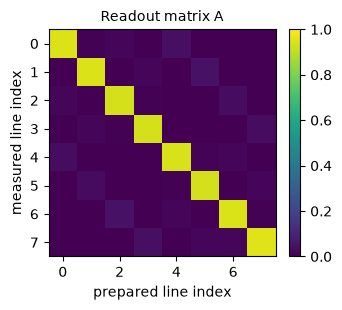

In [4]:
p = calibration["profile"]
measured = NoiseProfile(epsilon=p["epsilon"], readout=tuple(map(tuple, p["readout"])), source=p["source"],
                        line_qubits=tuple(p["line_qubits"]))
print(f"ε = {measured.epsilon:.3f}")
print("correct readout per line index:", [f"{measured.readout[i][i]:.3f}" for i in range(8)])
print(f"cutoffs at {first['shots']} shots: {first['cutoffs']}")
needed = measured.shots_needed(0.01, first["budget"])
print(f"shots needed for ≤1% misses with this noise: {needed or 'more than 16384'}")

fig, ax = plt.subplots(figsize=(3.6, 3.2))
im = ax.imshow(measured.readout, cmap="viridis", vmin=0, vmax=1)
ax.set_xlabel("prepared line index")
ax.set_ylabel("measured line index")
ax.set_title("Readout matrix A", fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

## Every board

board      label      true   confirmed rejected  on true lines  verdict
XOXOXXOOX  double_win [5, 6] [5, 6]    []                57.7%  correct
XXXOXOOOX  double_win [0, 6] [0, 6]    []                60.2%  correct
XO..X.O.X  single_win [6]    [6]       []                44.2%  correct
XOXO..XXO  no_win     []     []        []                14.2%  correct
XOOXOOXXX  double_win [2, 3] [2, 3]    []                57.4%  correct
OX.XXXO.O  single_win [1]    [1]       []                39.3%  correct
.OX.O.X.X  no_win     []     []        []                14.5%  correct
..OXXXO..  single_win [1]    [1]       []                37.4%  correct
XXO..OX..  no_win     []     []        []                14.3%  correct


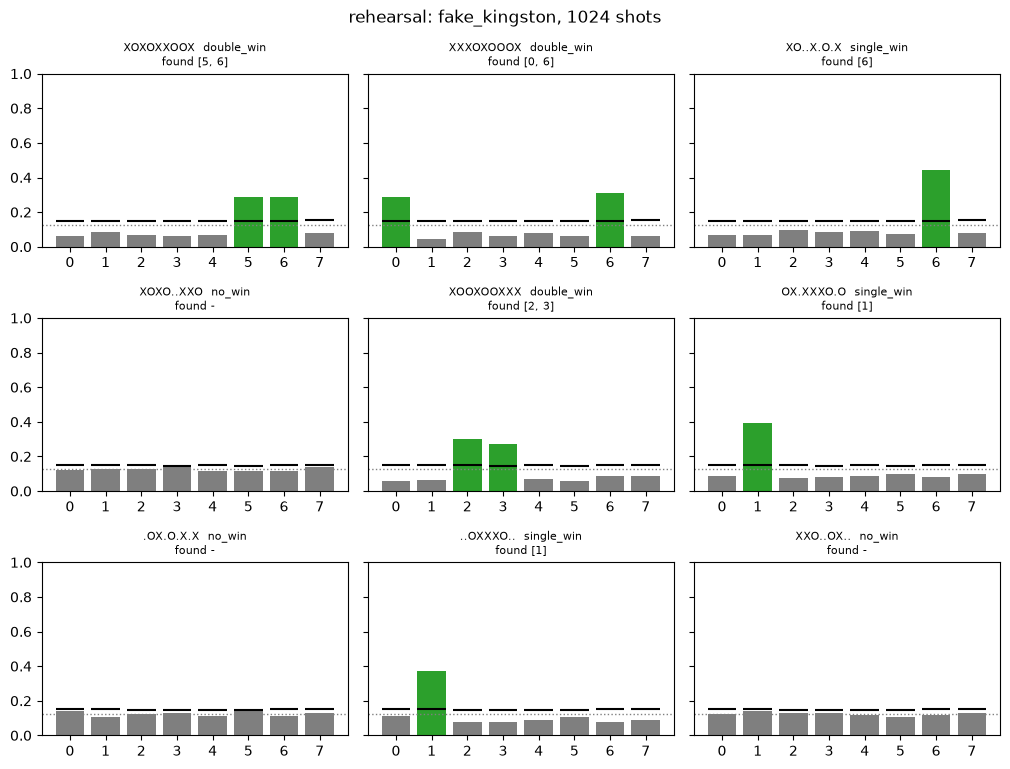

In [5]:
print(f"{'board':10} {'label':10} {'true':6} {'confirmed':9} {'rejected':8}  {'on true lines':>13}  verdict")
for r in detections:
    true, found = set(r["true_lines"]), set(r["lines"])
    share = sum(r["counts"][i] for i in true) / r["shots"] if true else max(r["counts"]) / r["shots"]
    if not true:
        verdict = "correct" if not found else "WRONG"
    else:
        verdict = "correct" if found == true else "partly missed" if found else "MISSED"
    print(f"{r['board'].replace(' ', '.'):10} {r['label']:10} {str(sorted(true)):6} {str(sorted(found)):9}"
          f" {str(r['rejected']):8}  {share:>13.1%}  {verdict}")

cols = 3
rows = -(-len(detections) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 2.6 * rows), sharey=True, squeeze=False)
for ax, r in zip(axes.flat, detections):
    true = set(r["true_lines"])
    colors = ["tab:green" if i in true else "tab:orange" if i in r["rejected"] else "tab:gray" for i in range(8)]
    ax.bar(range(8), [c / r["shots"] for c in r["counts"]], color=colors)
    ax.hlines([k / r["shots"] for k in r["cutoffs"]], [i - 0.4 for i in range(8)], [i + 0.4 for i in range(8)],
              color="black", linewidth=1.5)
    ax.axhline(1 / 8, color="gray", linestyle=":", linewidth=1)
    ax.set_title(f"{r['board'].replace(' ', '.')}  {r['label']}\nfound {r['lines'] or '-'}", fontsize=8)
    ax.set_xticks(range(8))
    ax.set_ylim(0, 1)
for ax in axes.flat[len(detections):]:
    ax.axis("off")
fig.suptitle(f"{MODE}: {first['backend']['name']}, {first['shots']} shots")
fig.tight_layout()
plt.show()

## Summary

A missed win is a board with a winner where no line reached its cutoff. A
false flag is a losing line that reached its cutoff; the classical check
rejects it, so it costs one extra check but never produces a wrong winner.

The budget allows about 0.1 false flags per board. Clearly more on no-win boards means the
noise is not spreading shots evenly over the losing lines, as the model assumes: some lines
pick up extra shots on boards without a winner. Calibrating on a known no-win board as well
would measure that bias directly.

In [6]:
print(f"{'label':11} {'boards':>6} {'win found':>10} {'all lines':>10} {'false flags':>11} {'checks/board':>12}")
for label in LABELS:
    group = [r for r in detections if r["label"] == label]
    if not group:
        continue
    found = sum(bool(r["lines"]) for r in group)
    every = sum(sorted(r["lines"]) == r["true_lines"] for r in group)
    flags = sum(len(r["rejected"]) for r in group)
    checks = sum(len(r["candidates"]) for r in group) / len(group)
    win = label != "no_win"
    print(f"{label:11} {len(group):>6} {f'{found}/{len(group)}' if win else '-':>10}"
          f" {f'{every}/{len(group)}' if win else '-':>10} {flags:>11} {checks:>12.2f}")
assert all(set(r["lines"]) <= set(r["true_lines"]) for r in detections), "a reported line was not a real win"

label       boards  win found  all lines false flags checks/board
no_win           3          -          -           0         0.00
single_win       3        3/3        3/3           0         1.00
double_win       3        3/3        3/3           0         2.00


## Measured vs predicted

For each board with a winner: the share of shots on its winning line(s),
measured in this job, next to the prediction of the device's published
calibration data and of the noise profile measured in the job itself.

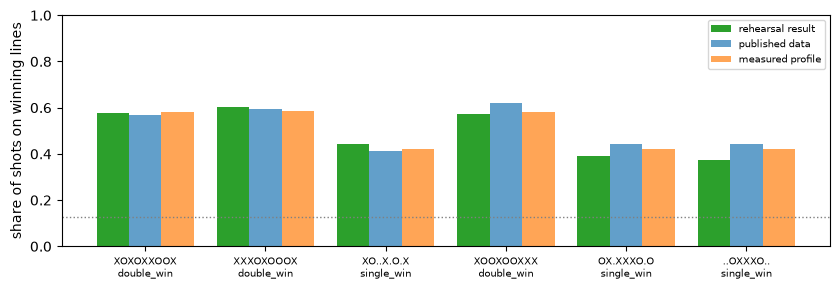

In [7]:
twin = get_backend(TWIN, seed=SEED)
published = NoiseProfile.from_backend(twin)
wins = [r for r in detections if r["true_lines"]]
x = np.arange(len(wins))
measured_share = [sum(r["counts"][i] for i in r["true_lines"]) / r["shots"] for r in wins]
model = {"published data": published, "measured profile": measured}
fig, ax = plt.subplots(figsize=(1.0 * len(wins) + 2.5, 3))
ax.bar(x - 0.27, measured_share, 0.27, label=f"{MODE} result", color="tab:green")
for k, (name, profile) in enumerate(model.items()):
    predicted = [sum(profile.predicted_for(r["true_lines"])[i] for i in r["true_lines"]) for r in wins]
    ax.bar(x + 0.27 * k, predicted, 0.27, label=name, alpha=0.7)
ax.axhline(1 / 8, color="gray", linestyle=":", linewidth=1)
ax.set_xticks(x, [f"{r['board'].replace(' ', '.')}\n{r['label']}" for r in wins], fontsize=7)
ax.set_ylabel("share of shots on winning lines")
ax.set_ylim(0, 1)
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

The published data usually predicts less signal than the device delivers
(ESP counts every gate error as fatal). The profile measured in the job is
fitted on one known board, so it should track the other boards closely; large
gaps on particular boards point to effects the simple model leaves out, such
as errors that depend on which board qubits are set.